# Staircase pilot: design table

2IFC detection staircase to choose `JITTER_SIZES_MS`. One row per trial.

- **Fixed here:** block, staircase (direction × copy), sentence type, interval, item, shifted presentation (1st / 2nd).
- **Filled in at run time:** `size_ms`, `shift_ms`, `response`, `correct` (left empty here).

Factors per staircase: 3 sentence types × 5 intervals × 3 reps = 45 trials; 4 staircases = 180 trials in 4 blocks.

In [1]:
# MODULES
import zlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from pathlib import Path

import os
PROJECT_DIR = '/Users/bastugb/Desktop/tapping_detection_sentences'
os.chdir(PROJECT_DIR)

In [2]:
# SETTINGS
VALID_GROUPS = ["speech", "acoustic"]

def ask_settings():
    pid = input("Enter participant ID: ").strip().upper()
    while not pid:
        pid = input("Participant ID cannot be empty. Enter participant ID: ").strip().upper()
    group = input(f"Enter experimental group ({' / '.join(VALID_GROUPS)}): ").strip().lower()
    while group not in VALID_GROUPS:
        group = input(f'"{group}" is not valid. Please type {" or ".join(VALID_GROUPS)}: ').strip().lower()
    return pid, group

PARTICIPANT_ID, GROUP = ask_settings()
SEED = None                         # None -> derived from PARTICIPANT_ID (reproducible)

IOI_MS     = 450
EVENT_MS   = 350
ISI_S      = 0.8                    # silence between the two presentations of a trial
RESPONSE_S = 1.5                    # assumed response time (duration estimate only)
ITI_S      = 0.8
OUTPUT_DIR = "staircase_pilot/design_tables_staircase"

In [3]:
# DESIGN CONSTANTS
N_WORDS    = 6
SOUND_S    = ((N_WORDS - 1) * IOI_MS + EVENT_MS) / 1000          # 2.6 s
TRIAL_S    = 2 * SOUND_S + ISI_S + RESPONSE_S + ITI_S            # ≈ 8.3 s

SENT_TYPES = ["2|4", "3|3", "word list"]
TYPE_CODE  = {"2|4": "S24", "3|3": "S33", "word list": "WL"}
N_ITEMS    = {"2|4": 18, "3|3": 18, "word list": 18}             # items per type: set to the final pilot counts
INTERVALS  = ["I1", "I2", "I3", "I4", "I5"]
DIRECTIONS = ["delay", "advance"]
COPIES     = [1, 2]
STAIRCASES = [f"{d}_{c}" for d in DIRECTIONS for c in COPIES]  # 4 interleaved staircases
N_REPS     = 3                                                   # per type × interval, per staircase
N_PER_SC   = len(SENT_TYPES) * len(INTERVALS) * N_REPS           # 45
N_BLOCKS   = 4
N_TRIALS   = N_PER_SC * len(STAIRCASES)                          # 180

def moved_word(interval):
    # 1-based word that moves for a shift at this interval (phase shift: it and all later words move)
    return int(interval[1:]) + 1

In [4]:
# DESIGN GENERATOR
def _cells_with_presentation(rng):
    # per direction: every type × interval cell has 6 trials (3 per copy) -> 3 with the shift in the 1st
    # presentation, 3 in the 2nd, split at random across the two copies.
    # Retry until each staircase has 22 or 23 trials with the shift in the 1st presentation.
    cells = [(st, iv) for st in SENT_TYPES for iv in INTERVALS]
    for _ in range(10_000):
        out = {sc: [] for sc in STAIRCASES}
        for d in DIRECTIONS:
            for c in cells:
                pres = rng.permutation([1] * N_REPS + [2] * N_REPS)
                out[f"{d}_1"] += [c + (int(p),) for p in pres[:N_REPS]]
                out[f"{d}_2"] += [c + (int(p),) for p in pres[N_REPS:]]
        if all(abs(sum(x[2] == 1 for x in v) - N_PER_SC / 2) <= 0.5 for v in out.values()):
            return {sc: [v[j] for j in rng.permutation(len(v))] for sc, v in out.items()}   # random order per staircase
    raise RuntimeError("Could not balance shifted presentation")


def _interleave(rng):
    # staircase label per trial: per block 11/11/11/12, each staircase gets its 12 in a different block
    sc_order = [STAIRCASES[j] for j in rng.permutation(len(STAIRCASES))]
    offset = int(rng.integers(N_BLOCKS))
    base = N_PER_SC // N_BLOCKS                                   # 11
    labels = []
    for b in range(N_BLOCKS):
        blk = [sc for i, sc in enumerate(sc_order) for _ in range(base + ((i + offset) % N_BLOCKS == b))]
        labels += [(b + 1, blk[j]) for j in rng.permutation(len(blk))]
    return labels


def make_design(participant_id, group, seed=None):
    if seed is None:
        seed = zlib.crc32(participant_id.encode())
    rng = np.random.default_rng(seed)

    queues = _cells_with_presentation(rng)
    labels = _interleave(rng)
    ids    = {st: [f"{TYPE_CODE[st]}_{i:02d}" for i in range(1, N_ITEMS[st] + 1)] for st in SENT_TYPES}
    decks  = {st: [] for st in SENT_TYPES}
    sc_n, seen, prev, rows = {sc: 0 for sc in STAIRCASES}, {}, None, []

    for trial, (block, sc) in enumerate(labels, start=1):
        st, iv, pres = queues[sc][sc_n[sc]]
        sc_n[sc] += 1
        # item: next from this type's shuffled deck; reshuffle when empty; never the same item twice in a row
        deck = decks[st]
        if not deck or (len(deck) == 1 and deck[0] == prev):
            deck += [ids[st][j] for j in rng.permutation(len(ids[st]))]
        k = next(i for i, x in enumerate(deck) if x != prev)
        item = deck.pop(k)
        prev = item
        seen[item] = seen.get(item, 0) + 1
        d, c = sc.split("_")
        rows.append({"participant": participant_id, "group": group, "seed": seed,
                     "trial": trial, "block": block,
                     "staircase": sc, "direction": d, "copy": int(c), "staircase_trial": sc_n[sc],
                     "sentence_type": st, "sentence_id": item, "exposure": seen[item],
                     "interval": iv, "moved_word": moved_word(iv), "shifted_presentation": pres,
                     # filled in at run time
                     "size_ms": np.nan, "shift_ms": np.nan, "response": np.nan, "correct": np.nan})
    return pd.DataFrame(rows)

In [5]:
# BUILD A TABLE FOR A PARTICIPANT
df = make_design(PARTICIPANT_ID, GROUP, SEED)
print(f"{len(df)} trials, seed = {df.seed.iloc[0]}")
print(f"trial ≈ {TRIAL_S:.1f} s -> trials ≈ {len(df) * TRIAL_S / 60:.1f} min "
      f"({N_BLOCKS} blocks × {len(df) // N_BLOCKS} trials, {len(df) // N_BLOCKS * TRIAL_S / 60:.1f} min per block)")
df.head(12)

180 trials, seed = 493207915
trial ≈ 8.3 s -> trials ≈ 24.9 min (4 blocks × 45 trials, 6.2 min per block)


,participant,group,seed,trial,block,staircase,direction,copy,staircase_trial,sentence_type,sentence_id,exposure,interval,moved_word,shifted_presentation,size_ms,shift_ms,response,correct
0,P01,speech,493207915,1,1,advance_2,advance,2,1,3|3,S33_05,1,I2,3,2,NaN,NaN,NaN,NaN
1,P01,speech,493207915,2,1,delay_2,delay,2,1,3|3,S33_01,1,I1,2,1,NaN,NaN,NaN,NaN
2,P01,speech,493207915,3,1,advance_1,advance,1,1,word list,WL_16,1,I2,3,2,NaN,NaN,NaN,NaN
3,P01,speech,493207915,4,1,delay_1,delay,1,1,word list,WL_12,1,I2,3,2,NaN,NaN,NaN,NaN
4,P01,speech,493207915,5,1,advance_1,advance,1,2,word list,WL_04,1,I3,4,2,NaN,NaN,NaN,NaN
5,P01,speech,493207915,6,1,advance_1,advance,1,3,word list,WL_18,1,I4,5,1,NaN,NaN,NaN,NaN
6,P01,speech,493207915,7,1,delay_1,delay,1,2,word list,WL_07,1,I1,2,1,NaN,NaN,NaN,NaN
7,P01,speech,493207915,8,1,delay_2,delay,2,2,2|4,S24_08,1,I3,4,1,NaN,NaN,NaN,NaN
8,P01,speech,493207915,9,1,advance_1,advance,1,4,3|3,S33_15,1,I3,4,2,NaN,NaN,NaN,NaN
9,P01,speech,493207915,10,1,advance_1,advance,1,5,2|4,S24_03,1,I5,6,2,NaN,NaN,NaN,NaN


In [ ]:
df

In [6]:
# BALANCE CHECKS
def check_balance(df, verbose=True):
    assert len(df) == N_TRIALS and df.trial.is_unique
    for sc in STAIRCASES:
        d = df[df.staircase == sc]
        assert len(d) == N_PER_SC, sc
        assert (d.staircase_trial.to_numpy() == np.arange(1, N_PER_SC + 1)).all(), sc
        g = d.groupby(["sentence_type", "interval"]).size()
        assert len(g) == 15 and (g == N_REPS).all(), sc                                   # 3 per type × interval
        n1 = (d.shifted_presentation == 1).sum()
        assert n1 in (N_PER_SC // 2, N_PER_SC // 2 + 1), (sc, n1)                       # 22 / 23
    for dr in DIRECTIONS:
        d = df[df.direction == dr]
        p = d.groupby(["sentence_type", "interval", "shifted_presentation"]).size()
        assert len(p) == 30 and (p == N_REPS).all(), dr                                  # 3 / 3 per cell and direction
    # blocks: 45 trials; each staircase 11 or 12 per block
    b = pd.crosstab(df.block, df.staircase)
    assert (b.sum(axis=1) == N_TRIALS // N_BLOCKS).all() and b.isin([11, 12]).all().all()
    # items: each type 60 trials, usage spread evenly
    for st in SENT_TYPES:
        u = df[df.sentence_type == st].sentence_id.value_counts().reindex(
            [f"{TYPE_CODE[st]}_{i:02d}" for i in range(1, N_ITEMS[st] + 1)], fill_value=0)
        assert u.sum() == N_TRIALS // len(SENT_TYPES), st
        assert u.max() - u.min() <= 1, (st, u.min(), u.max())
    assert (df.sentence_id.values[1:] != df.sentence_id.values[:-1]).all(), "item repeated back-to-back"
    if verbose:
        print("✓ All balance checks passed")

check_balance(df)

✓ All balance checks passed


In [7]:
# FIGURE STYLE
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#8a8984", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e6e5e0", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "legend.frameon": False,
})
ST_COLORS = {"2|4": "#2a78d6", "3|3": "#eb6834", "word list": "#1baf7a"}
SC_COLORS = {"delay_1": "#1f5ea8", "delay_2": "#9cc2ef", "advance_1": "#b8431a", "advance_2": "#f2b38f"}
INK = "#0b0b0b"


def count_heatmap(ax, table, title, vmax=None):
    vmax = vmax or max(table.values.max(), 1) * 1.3
    ax.imshow(table.values.astype(float), cmap="Blues", vmin=0, vmax=vmax, aspect="auto")
    for (i, j), v in np.ndenumerate(table.values):
        ax.text(j, i, int(v), ha="center", va="center", fontsize=9, color="white" if v > vmax * 0.6 else INK)
    ax.set_xticks(range(table.shape[1]), table.columns, fontsize=8)
    ax.set_yticks(range(table.shape[0]), table.index, fontsize=8)
    ax.grid(False); ax.set_title(title, loc="left", fontsize=10)
    for s in ax.spines.values(): s.set_visible(False)

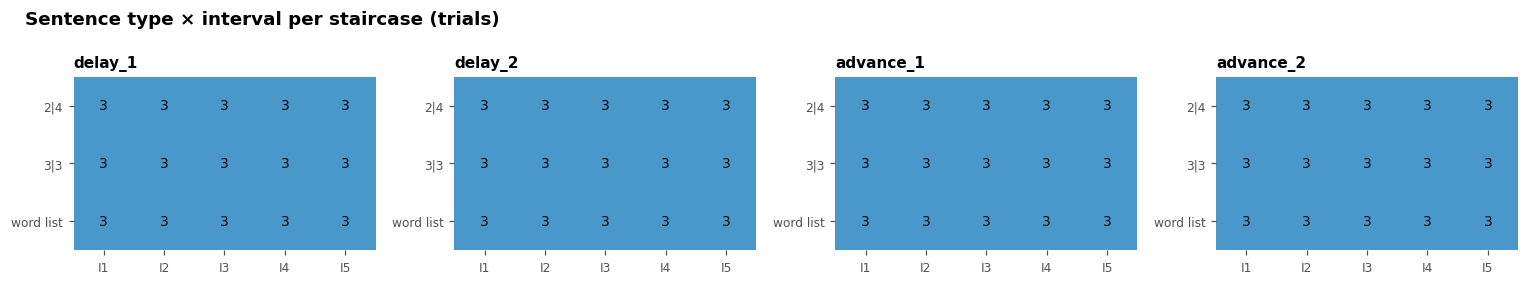

In [8]:
# 1. SENTENCE TYPE × INTERVAL PER STAIRCASE (every cell should be 3)
fig, axes = plt.subplots(1, 4, figsize=(14, 2.6))
for ax, sc in zip(axes, STAIRCASES):
    d = df[df.staircase == sc]
    t = pd.crosstab(d.sentence_type, d.interval).reindex(index=SENT_TYPES, columns=INTERVALS, fill_value=0)
    count_heatmap(ax, t, sc, vmax=5)
fig.suptitle("Sentence type × interval per staircase (trials)", x=0.02, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()

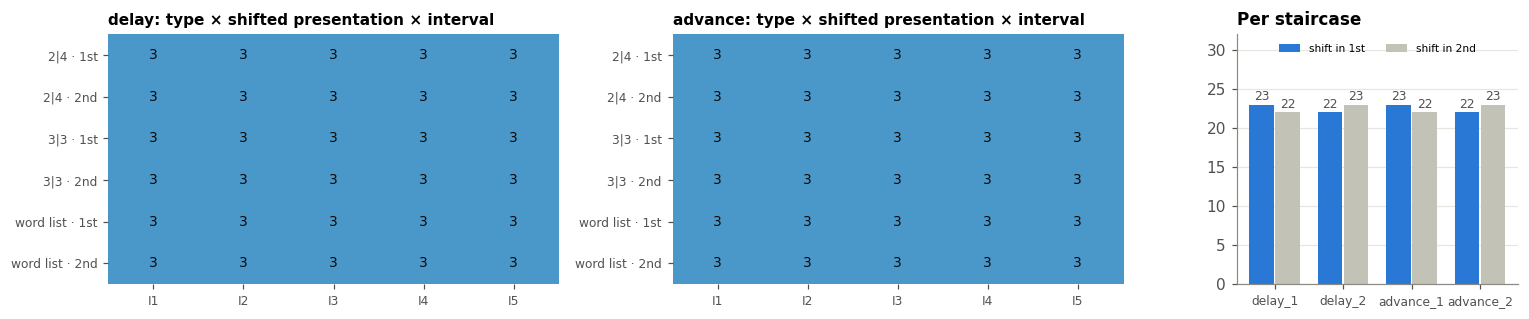

In [9]:
# 2. SHIFTED PRESENTATION (1st / 2nd)
#    left: per direction, every type × interval cell should be 3 / 3; right: per staircase 22 / 23
fig = plt.figure(figsize=(14, 3.0))
gs = fig.add_gridspec(1, 3, width_ratios=[1.6, 1.6, 1])
for k, dr in enumerate(DIRECTIONS):
    ax = fig.add_subplot(gs[0, k])
    d = df[df.direction == dr]
    t = pd.crosstab([d.sentence_type, d.shifted_presentation], d.interval).reindex(columns=INTERVALS)
    t = t.reindex([(st, p) for st in SENT_TYPES for p in (1, 2)], fill_value=0)
    t.index = [f"{st} · {'1st' if p == 1 else '2nd'}" for st, p in t.index]
    count_heatmap(ax, t, f"{dr}: type × shifted presentation × interval", vmax=5)
ax = fig.add_subplot(gs[0, 2])
t = pd.crosstab(df.staircase, df.shifted_presentation).reindex(STAIRCASES)
x = np.arange(len(STAIRCASES))
for i, (p, c) in enumerate(((1, "#2a78d6"), (2, "#c3c2b7"))):
    bars = ax.bar(x + (i - 0.5) * 0.38, t[p], 0.36, color=c, label=f"shift in {'1st' if p == 1 else '2nd'}")
    ax.bar_label(bars, fontsize=8, color="#52514e", padding=1)
ax.set_xticks(x, STAIRCASES, fontsize=8); ax.set_ylim(0, 32); ax.set_title("Per staircase", loc="left")
ax.legend(fontsize=7, loc="upper center", ncols=2)
plt.tight_layout(); plt.show()

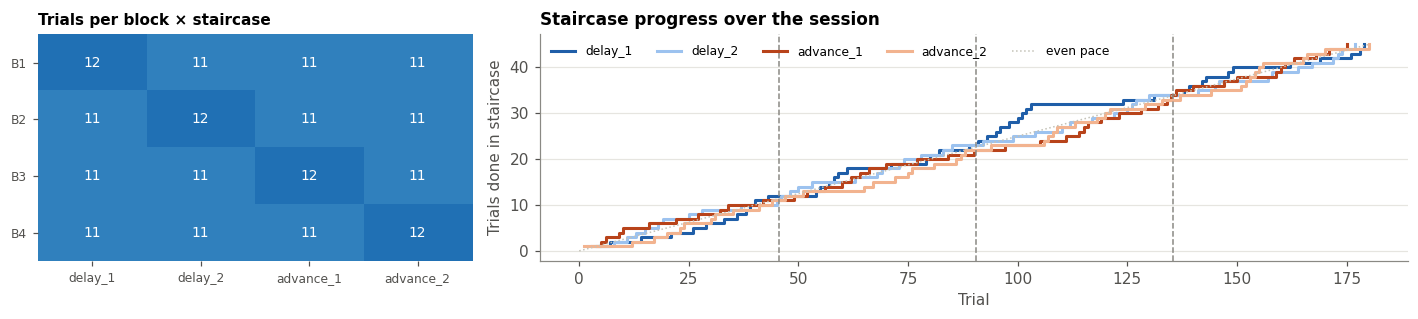

In [10]:
# 3. BLOCKS × STAIRCASE (11 or 12 each; each staircase has its 12 in a different block)
#    and how far each staircase has progressed over the session (lines should run close together)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.0), gridspec_kw={"width_ratios": [1, 2]})
t = pd.crosstab(df.block, df.staircase)[STAIRCASES]; t.index = [f"B{b}" for b in t.index]
count_heatmap(axes[0], t, "Trials per block × staircase", vmax=16)
for sc in STAIRCASES:
    d = df[df.staircase == sc]
    axes[1].step(d.trial, d.staircase_trial, where="post", color=SC_COLORS[sc], lw=2, label=sc)
for b in df.groupby("block").trial.min().iloc[1:]:
    axes[1].axvline(b - 0.5, color="#8a8984", ls="--", lw=1)
axes[1].plot([0, N_TRIALS], [0, N_PER_SC], color="#c3c2b7", lw=1, ls=":", label="even pace")
axes[1].set_xlabel("Trial"); axes[1].set_ylabel("Trials done in staircase")
axes[1].set_title("Staircase progress over the session", loc="left"); axes[1].legend(fontsize=8, ncols=5, loc="upper left")
plt.tight_layout(); plt.show()

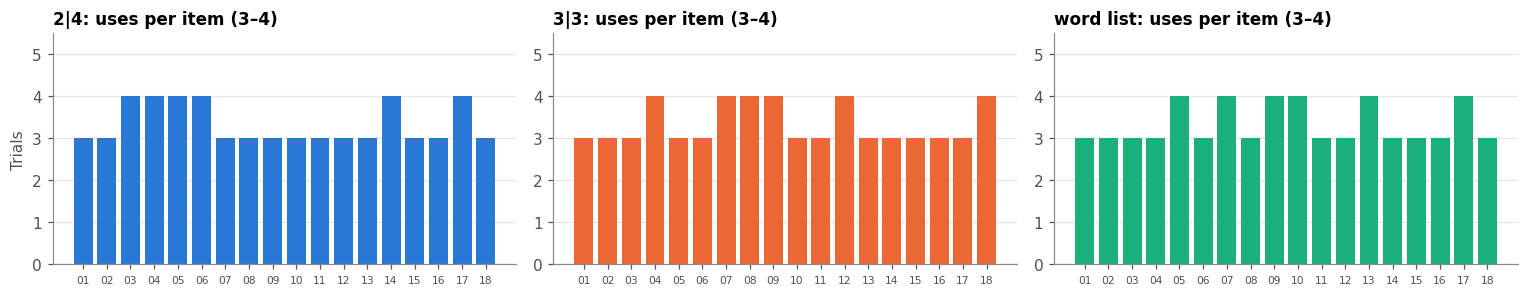

In [11]:
# 4. ITEM USAGE (per type: every item used about equally; exposure = how often the item has been heard so far)
fig, axes = plt.subplots(1, 3, figsize=(14, 2.8))
for ax, st in zip(axes, SENT_TYPES):
    ids = [f"{TYPE_CODE[st]}_{i:02d}" for i in range(1, N_ITEMS[st] + 1)]
    u = df[df.sentence_type == st].sentence_id.value_counts().reindex(ids, fill_value=0)
    ax.bar(range(len(ids)), u.values, 0.8, color=ST_COLORS[st])
    ax.set_xticks(range(len(ids)), [i.split("_")[1] for i in ids], fontsize=7)
    ax.set_ylim(0, u.max() + 1.5); ax.set_title(f"{st}: uses per item ({u.min()}–{u.max()})", loc="left")
axes[0].set_ylabel("Trials")
plt.tight_layout(); plt.show()

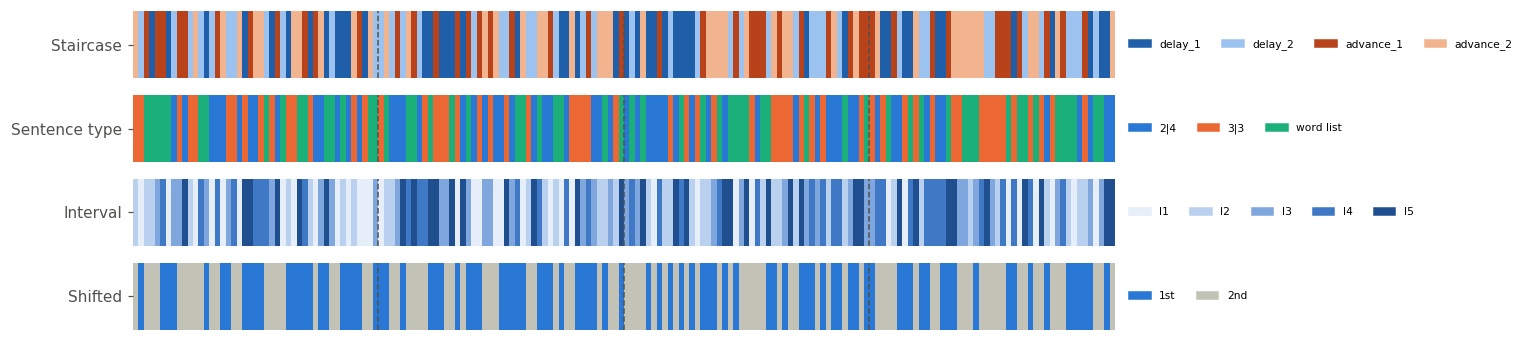

In [12]:
# 5. TRIAL SEQUENCE (staircase, sentence type, interval, shifted presentation; dashed = block boundary)
rows = [("Staircase", df.staircase.map({s: i for i, s in enumerate(STAIRCASES)}), [SC_COLORS[s] for s in STAIRCASES], STAIRCASES),
        ("Sentence type", df.sentence_type.map({s: i for i, s in enumerate(SENT_TYPES)}), [ST_COLORS[s] for s in SENT_TYPES], SENT_TYPES),
        ("Interval", df.interval.map({s: i for i, s in enumerate(INTERVALS)}),
         ["#e6eef9", "#b9d0ef", "#7fa7dd", "#3f78c4", "#1f4f8f"], INTERVALS),
        ("Shifted", df.shifted_presentation - 1, ["#2a78d6", "#c3c2b7"], ["1st", "2nd"])]
bounds = np.flatnonzero(np.diff(df.block.values)) + 1
fig, axes = plt.subplots(len(rows), 1, figsize=(14, 3.2), sharex=True)
for a, (lab, vals, cols, names) in zip(axes, rows):
    a.imshow(vals.values[None, :], aspect="auto", cmap=ListedColormap(cols), vmin=0, vmax=len(names) - 1, interpolation="nearest")
    a.set_yticks([0], [lab]); a.set_xticks([]); a.grid(False)
    for s in a.spines.values(): s.set_visible(False)
    for b in bounds: a.axvline(b - 0.5, color="#52514e", ls="--", lw=1)
    a.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in cols], names, loc="center left",
             bbox_to_anchor=(1.005, 0.5), fontsize=7, ncols=len(names))
plt.tight_layout(); plt.show()

In [13]:
# 6. ROBUSTNESS: balance checks for 200 participant IDs
for i in range(1, 201):
    check_balance(make_design(f"P{i:02d}", "speech"), verbose=False)
print("✓ Balance checks passed for 200 participant IDs")

✓ Balance checks passed for 200 participant IDs


In [ ]:
# SAVE
Path(OUTPUT_DIR).mkdir(parents=True, exist_ok=True)
path = Path(OUTPUT_DIR) / f"staircase_{PARTICIPANT_ID}_{GROUP}.csv"
df.to_csv(path, index=False)
print("Saved", path)